# 01 — EDA: volume, rótulo, maturação e drift natural por safra

Exploração do Lending Club (empréstimos aceitos). **Só agregados** são exibidos — nenhuma linha individual.
A lógica de carga, alvo, maturação e separação vem de `src/data/`; este notebook não reimplementa nada do pipeline.

Perguntas:
1. Quanto volume há por safra e qual fatia está no escopo (aplicação individual)?
2. Quão imaturo é o rótulo nas safras recentes (censura)?
3. Quais features de originação existem em cada época (nulos estruturais)?
4. Quanto a população já se desloca naturalmente em relação à referência (prévia do PSI)?

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import get_settings
from src.data.features import CATEGORICAL_FEATURES, add_derived_features, model_feature_columns, numeric_features
from src.data.load import load_dataset
from src.data.target import is_mature, map_target

pd.set_option("display.width", 160, "display.max_columns", 40)
settings = get_settings()
raw, snapshot = load_dataset(settings.raw_data_path)
raw["target"] = map_target(raw["loan_status"])
raw["is_mature"] = is_mature(raw["issue_d"], raw["term"], snapshot)
raw["year"] = raw["issue_d"].dt.year
raw = add_derived_features(raw)
print(f"linhas={len(raw):,}  snapshot={snapshot.date()}  safras={raw['issue_d'].min():%Y-%m}..{raw['issue_d'].max():%Y-%m}")

linhas=2,260,668  snapshot=2019-03-01  safras=2007-06..2018-12


## 1. Volume por safra e escopo

In [2]:
vol = pd.crosstab(raw["year"], raw["application_type"], margins=True, margins_name="total")
vol

application_type,Individual,Joint App,total
year,,,
2007,603,0,603
2008,2393,0,2393
2009,5281,0,5281
2010,12537,0,12537
2011,21721,0,21721
2012,53367,0,53367
2013,134814,0,134814
2014,235629,0,235629
2015,420584,511,421095


## 2. Status do rótulo por safra (censura) — aplicações individuais

In [3]:
ind = raw[raw["application_type"] == "Individual"]
status = pd.crosstab(ind["year"], ind["loan_status"], normalize="index").mul(100).round(1)
status[["Fully Paid", "Charged Off", "Current", "Late (31-120 days)", "In Grace Period"]]

loan_status,Fully Paid,Charged Off,Current,Late (31-120 days),In Grace Period
year,,,,,
2007,34.2,7.5,0.0,0.0,0.0
2008,55.0,10.3,0.0,0.0,0.0
2009,78.1,11.2,0.0,0.0,0.0
2010,80.2,11.9,0.0,0.0,0.0
2011,84.8,15.2,0.0,0.0,0.0
2012,83.8,16.2,0.0,0.0,0.0
2013,84.4,15.6,0.0,0.0,0.0
2014,77.2,17.5,5.1,0.1,0.1
2015,71.2,18.0,10.3,0.3,0.1


In [4]:
by_year = ind.groupby("year").agg(
    loans=("target", "size"),
    resolved_share=("target", lambda s: s.notna().mean()),
    mature_share=("is_mature", "mean"),
    bad_rate_resolved=("target", "mean"),
)
by_year["bad_rate_mature"] = ind[ind["is_mature"]].groupby("year")["target"].mean()
by_year.round(4)

,loans,resolved_share,mature_share,bad_rate_resolved,bad_rate_mature
year,,,,,
2007,603,1.0000,1.0000,0.2620,0.2620
2008,2393,1.0000,1.0000,0.2073,0.2073
2009,5281,1.0000,1.0000,0.1369,0.1369
2010,12537,1.0000,1.0000,0.1401,0.1401
2011,21721,1.0000,1.0000,0.1518,0.1518
2012,53367,1.0000,1.0000,0.1620,0.1620
2013,134814,0.9999,1.0000,0.1560,0.1560
2014,235629,0.9468,0.7465,0.1845,0.1463
2015,420584,0.8920,0.6727,0.2018,0.1488


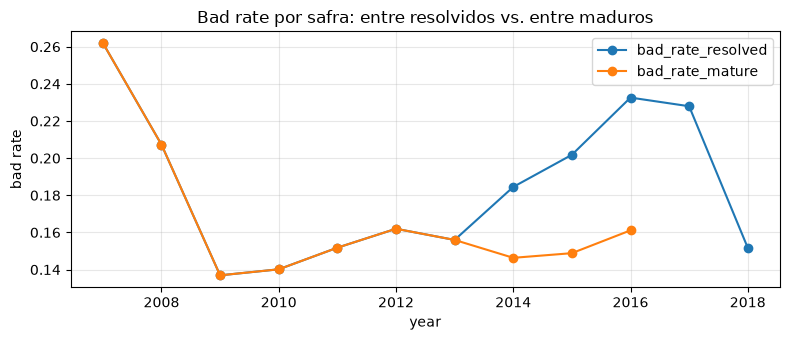

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
by_year[["bad_rate_resolved", "bad_rate_mature"]].plot(ax=ax, marker="o")
ax.set_ylabel("bad rate"); ax.set_title("Bad rate por safra: entre resolvidos vs. entre maduros")
ax.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Leitura.** Entre os *resolvidos*, o bad rate das safras recentes é inflado: quem já resolveu um empréstimo jovem é,
desproporcionalmente, quem inadimpliu cedo (quem paga em dia ainda está `Current`). Entre os *maduros* (prazo
integral decorrido até o snapshot) a comparação é justa, mas só existe até ~2016 (36 m) e ~2014 (60 m).
Consequência para o projeto: desempenho com rótulo (L4) em produção natural só é mensurável com atraso — o
*label lag* é real, não só simulado.

## 3. Maturação por prazo

In [6]:
ind.pivot_table(index="year", columns="term", values="is_mature", aggfunc="mean").round(3)

term,36,60
year,,
2007,1.000,NaN
2008,1.000,NaN
2009,1.000,NaN
2010,1.000,1.000
2011,1.000,1.000
2012,1.000,1.000
2013,1.000,1.000
2014,1.000,0.183
2015,1.000,0.000


## 4. Nulos estruturais nas features do modelo

In [7]:
feats = model_feature_columns()
nulls = ind.groupby("year")[feats].apply(lambda g: g.isna().mean()).T.round(2)
nulls[(nulls.loc[:, 2013:] > 0.02).any(axis=1) | (nulls.loc[:, :2012] > 0.5).any(axis=1)]

year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
emp_length,0.00,0.00,0.00,0.03,0.03,0.04,0.04,0.05,0.06,0.06,0.06,0.08
mths_since_last_delinq,0.06,0.38,0.67,0.64,0.66,0.59,0.57,0.49,0.48,0.47,0.50,0.55
mort_acc,1.00,1.00,1.00,1.00,1.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00
pub_rec_bankruptcies,0.97,0.33,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
acc_open_past_24mths,1.00,1.00,1.00,1.00,1.00,0.14,0.00,0.00,0.00,0.00,0.00,0.00
bc_util,1.00,1.00,1.00,1.00,1.00,0.15,0.01,0.01,0.01,0.01,0.01,0.01
avg_cur_bal,1.00,1.00,1.00,1.00,1.00,0.52,0.00,0.00,0.00,0.00,0.00,0.00
tot_hi_cred_lim,1.00,1.00,1.00,1.00,1.00,0.52,0.00,0.00,0.00,0.00,0.00,0.00
num_actv_rev_tl,1.00,1.00,1.00,1.00,1.00,0.52,0.00,0.00,0.00,0.00,0.00,0.00
percent_bc_gt_75,1.00,1.00,1.00,1.00,1.00,0.15,0.01,0.01,0.01,0.01,0.01,0.01


Features de bureau (`acc_open_past_24mths`, `bc_util`, `mort_acc`, `tot_*`…) são nulas antes de 2012 e parciais em 2012 —
por isso a referência começa em 2013. `mths_since_last_delinq` e `mths_since_recent_inq` têm nulo *informativo*
(nunca houve o evento).

## 5. Cardinalidade e níveis novos das categóricas

In [8]:
ind.groupby("year")[list(CATEGORICAL_FEATURES) + ["addr_state"]].nunique().T

year,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
grade,7,7,7,7,7,7,7,7,7,7,7,7
home_ownership,4,5,4,4,4,5,3,4,4,4,5,4
verification_status,1,3,3,3,3,3,3,3,3,3,3,3
purpose,13,14,14,14,13,13,13,13,14,13,14,13
addr_state,38,47,43,44,45,46,49,49,49,50,50,50


In [9]:
ref = ind[ind["year"] == 2013]
rows = []
for col in CATEGORICAL_FEATURES:
    ref_levels = set(ref[col].dropna().unique())
    for year in range(2014, 2019):
        cur = set(ind.loc[ind["year"] == year, col].dropna().unique())
        rows.append({"feature": col, "year": year, "levels": len(cur), "new_vs_2013": sorted(cur - ref_levels)})
pd.DataFrame(rows).pivot(index="feature", columns="year", values="new_vs_2013")

year,2014,2015,2016,2017,2018
feature,,,,,
grade,[],[],[],[],[]
home_ownership,[ANY],[ANY],[ANY],"[ANY, NONE]",[ANY]
purpose,[],[educational],[],[educational],[]
verification_status,[],[],[],[],[]


## 6. Distribuições: referência (2013) × produção

In [10]:
key = ["int_rate", "annual_inc", "dti", "fico_range_low", "loan_amnt", "revol_util", "bc_util"]
q = ind[ind["year"].isin([2013, 2016, 2018])].groupby("year")[key].quantile([0.1, 0.5, 0.9]).unstack(level=1)
q.round(2)

int_rate               annual_inc                      dti               fico_range_low               loan_amnt                   revol_util              \
          0.1    0.5    0.9        0.1      0.5       0.9   0.1    0.5    0.9            0.1    0.5    0.9       0.1      0.5      0.9        0.1   0.5   0.9   
year                                                                                                                                                            
2013     8.90  14.33  20.80    35000.0  64000.0  120000.0  7.32  16.89  27.77          665.0  690.0  730.0    5000.0  13000.0  26000.0       27.5  60.3  87.6   
2016     7.39  11.99  19.99    35000.0  67000.0  131000.0  7.66  18.12  30.32          665.0  690.0  740.0    5000.0  12000.0  28000.0       18.1  50.2  83.9   
2018     6.67  11.80  19.92    35000.0  70000.0  140000.0  6.48  17.04  29.73          665.0  700.0  755.0    5000.0  12600.0  30000.0       11.7  41.8  79.0   

     bc_util              
         0.1   0.5   0.9  
year                      
2013    28.9  72.0  96.3  
2016    17.9  60.6  94.9  
2018    10.8  48.4  90.9

## 7. Prévia do drift natural: PSI anual contra a referência 2013

PSI com bins de **decis da referência** (fixos), ε = 1e-4 em bin vazio, categorias tratadas como bins. Esta é uma
prévia exploratória; a implementação oficial (com testes e cruzamento com Evidently) é da F5.

In [11]:
EPS = 1e-4

def psi(ref_s, cur_s, categorical):
    if categorical:
        r, c = ref_s.value_counts(normalize=True), cur_s.value_counts(normalize=True)
        idx = r.index.union(c.index)
        r, c = r.reindex(idx, fill_value=0), c.reindex(idx, fill_value=0)
    else:
        edges = np.unique(np.nanquantile(ref_s.dropna(), np.linspace(0, 1, 11)))
        edges[0], edges[-1] = -np.inf, np.inf
        r = pd.cut(ref_s.dropna(), edges).value_counts(normalize=True, sort=False)
        c = pd.cut(cur_s.dropna(), edges).value_counts(normalize=True, sort=False)
    r, c = r.clip(lower=EPS), c.clip(lower=EPS)
    return float(((c - r) * np.log(c / r)).sum())

psi_tab = pd.DataFrame({
    year: {f: psi(ref[f], ind.loc[ind["year"] == year, f], f in CATEGORICAL_FEATURES) for f in feats}
    for year in range(2014, 2019)
}).round(3)
psi_tab.sort_values(2018, ascending=False).head(15)

,2014,2015,2016,2017,2018
verification_status,0.244,0.255,0.239,0.291,0.472
percent_bc_gt_75,0.010,0.046,0.120,0.220,0.408
revol_util,0.020,0.051,0.129,0.227,0.401
bc_util,0.009,0.038,0.105,0.207,0.392
int_rate,0.114,0.225,0.255,0.180,0.273
grade,0.029,0.027,0.018,0.054,0.204
inq_last_6mths,0.002,0.044,0.048,0.071,0.112
fico_range_low,0.024,0.020,0.021,0.044,0.112
mort_acc,0.001,0.012,0.035,0.072,0.102
loan_amnt,0.010,0.014,0.029,0.065,0.088


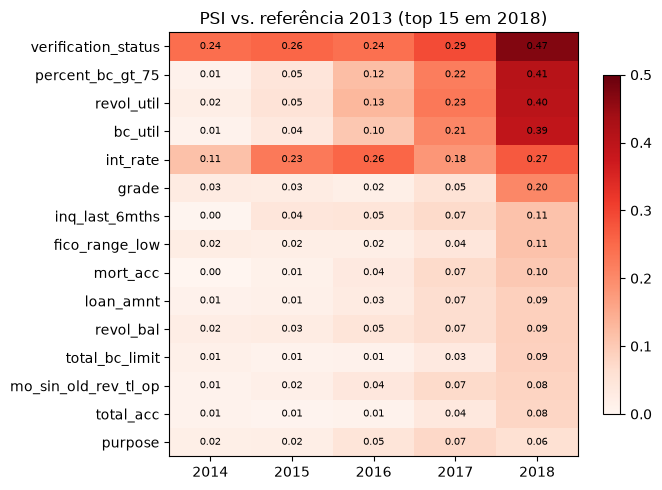

In [12]:
top = psi_tab.sort_values(2018, ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(top.values, cmap="Reds", vmin=0, vmax=0.5, aspect="auto")
ax.set_xticks(range(top.shape[1]), top.columns); ax.set_yticks(range(top.shape[0]), top.index)
for i in range(top.shape[0]):
    for j in range(top.shape[1]):
        ax.text(j, i, f"{top.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("PSI vs. referência 2013 (top 15 em 2018)"); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

In [13]:
bands = pd.cut(psi_tab.stack(), [-np.inf, 0.10, 0.25, np.inf], labels=["< 0,10", "0,10–0,25", "> 0,25"])
bands.groupby(level=1).value_counts().unstack()

,"< 0,10","0,10–0,25","> 0,25"
2014,31,2,0
2015,31,1,1
2016,28,4,1
2017,28,4,1
2018,24,4,5


## Conclusões (insumo dos ADRs 0003–0005 e do data card)

- O eixo temporal é real e longo (2007–2018), mas só a partir de 2013 as features de bureau estão completas → **referência = safra 2013**.
- O rótulo das safras ≥ 2016 é fortemente censurado; bad rate entre resolvidos superestima o risco → **maturação por prazo** define o que é rótulo confiável.
- Já existe **drift natural** relevante entre 2013 e 2018 (ver PSI acima) — S5 (produção natural) terá sinal real para o detector.
- Categorias novas aparecem na produção (ver seção 5) → são casos para o contrato *soft* da F3.